<a href="https://colab.research.google.com/github/Poojaahegde/Managerial-Economics/blob/master/Uber_Python_Code_ECO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uber pricing: reproduce the calculations and chart
Open this notebook in Google Colab and run the two code cells in order.
The inputs are transcribed from the paper’s Appendix A, attributed to [Cohen et al. (2016)](https://www.nber.org/papers/w22627). The 11-point demand schedule is derived from elasticity estimates; it is not additional observed data.
The code reports elasticity, regression coefficients, R² and standard errors, then saves the chart and a CSV file.


In [1]:
%pip -q install numpy matplotlib


Arc elasticity: -0.525 (inelastic)
Linear: Q = 69.080 -0.950 P; R² = 0.913
Log-log: ln Q = 5.981 -0.700 ln P; R² = 0.983
Observed groups: ln Q = 5.447 -0.503 ln P; R² = 0.986
Coefficient standard errors [intercept, slope]:
  Linear: [2.59102052 0.09747327]  Log-log: [0.09529502 0.03031944]  Observed: [0.1838482 0.0601176]
The derived schedule's R² measures curve fit, not independent causal evidence.
Saved Uber_Python_Chart.png and Uber_Demand_Schedule.csv


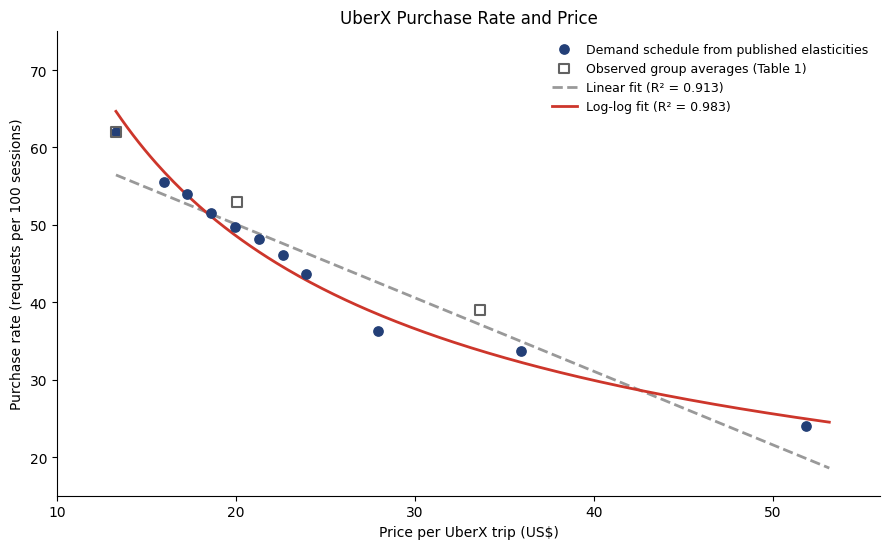

In [2]:
"""Reproduce the Uber paper's elasticity, OLS fits, and Figure B1.
Inputs below are transcribed from the existing paper's Appendix A and attributed
there to Cohen et al. (2016), https://www.nber.org/papers/w22627.
The 11-point demand schedule is constructed, not 11 independent observations.
"""

from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt

base_fare = 13.30
base_purchase_rate = 62.0  # Purchases/requests per 100 sessions.
surge = np.array([1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 2.1, 2.7, 3.9])
elasticity = np.array([np.nan, -.52, -.34, -.58, -.49, -.50,
                       -.68, -.89, -1.01, -.25, -.65])
price = base_fare * surge
quantity = np.empty(len(price))
quantity[0] = base_purchase_rate
for i in range(1, len(price)):
    price_change = price[i] / price[i - 1] - 1
    quantity[i] = quantity[i - 1] * (1 + elasticity[i] * price_change)

observed_surge = np.array([1.000, 1.509, 2.531])
observed_price = base_fare * observed_surge
observed_quantity = np.array([62.0, 53.0, 39.0])

def ols(x, y):
    """Fit y = intercept + slope*x, including residual-based standard errors."""
    design = np.column_stack([np.ones(len(x)), x])
    beta = np.linalg.lstsq(design, y, rcond=None)[0]
    residual = y - design @ beta
    sse = residual @ residual
    r_squared = 1 - sse / np.sum((y - y.mean()) ** 2)
    se = np.sqrt(np.diag((sse / (len(x) - 2)) *
                         np.linalg.inv(design.T @ design)))
    return beta, r_squared, se

linear, r2_linear, se_linear = ols(price, quantity)
loglog, r2_loglog, se_loglog = ols(np.log(price), np.log(quantity))
observed, r2_observed, se_observed = ols(
    np.log(observed_price), np.log(observed_quantity))
arc_elasticity = ((observed_quantity[-1] - observed_quantity[0]) /
                  observed_quantity[[0, -1]].mean()) / (
                 (observed_price[-1] - observed_price[0]) /
                  observed_price[[0, -1]].mean())

print(f"Arc elasticity: {arc_elasticity:.3f} (inelastic)")
print(f"Linear: Q = {linear[0]:.3f} {linear[1]:+.3f} P; R² = {r2_linear:.3f}")
print(f"Log-log: ln Q = {loglog[0]:.3f} {loglog[1]:+.3f} ln P; R² = {r2_loglog:.3f}")
print(f"Observed groups: ln Q = {observed[0]:.3f} {observed[1]:+.3f} ln P; R² = {r2_observed:.3f}")
print("Coefficient standard errors [intercept, slope]:")
print("  Linear:", se_linear, " Log-log:", se_loglog, " Observed:", se_observed)
print("The derived schedule's R² measures curve fit, not independent causal evidence.")

grid = np.linspace(price.min(), price.max() * 1.025, 250)
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.scatter(price, quantity, color="#233f77", s=45,
           label="Demand schedule from published elasticities", zorder=3)
ax.scatter(observed_price, observed_quantity, marker="s", facecolors="none",
           edgecolors="#626262", s=50, linewidths=1.5,
           label="Observed group averages (Table 1)", zorder=4)
ax.plot(grid, linear[0] + linear[1] * grid, color="#999999", linestyle="--",
        linewidth=2, label=f"Linear fit (R² = {r2_linear:.3f})")
ax.plot(grid, np.exp(loglog[0]) * grid ** loglog[1], color="#cd362b",
        linewidth=2, label=f"Log-log fit (R² = {r2_loglog:.3f})")
ax.set(xlabel="Price per UberX trip (US$)",
       ylabel="Purchase rate (requests per 100 sessions)",
       title="UberX Purchase Rate and Price", xlim=(10, 56), ylim=(15, 75))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", fontsize=9)
fig.tight_layout()
fig.savefig("Uber_Python_Chart.png", dpi=200)
with Path("Uber_Demand_Schedule.csv").open("w", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(["Surge", "Price_USD", "Elasticity_applied", "Requests_per_100_sessions"])
    writer.writerows(zip(surge, price, elasticity, quantity))
print("Saved Uber_Python_Chart.png and Uber_Demand_Schedule.csv")
plt.show()
